In [110]:
from pathlib import Path
import pandas as pd

root = Path("/work/magroup/skrieger/Syndri/data/datasets")
datasets = [
    "agingbrain_merfish",
    "brain_merfish",
    "nsclc_cosmx",
    "breast_xenium",
]

frames = []
for dataset in datasets:
    for path in sorted(
        (root / dataset / "results/metrics/non_tcell").glob(
            "*/non_tcell_metrics.csv"
        )
    ):
        frame = pd.read_csv(path)
        frame["dataset"] = dataset
        frame["slice"] = path.parent.name
        frames.append(frame)

if not frames:
    raise FileNotFoundError("No non-T-cell metric CSVs found.")

metrics = pd.concat(frames, ignore_index=True)

failed = metrics["error"].fillna("").ne("")
# display(metrics.loc[failed, ["dataset", "slice", "case", "error"]])

valid_metrics = metrics.loc[~failed].copy()

metric_columns = [
    "silhouette_score",
    "calinski_harabasz",
    "davies_bouldin",
    "leiden_nmi_vs_label",
    "leiden_adjusted_rand_vs_label",
]

display(
    valid_metrics[
        ["dataset", "slice", "case", "target_removed_fraction",
         "achieved_removed_fraction", *metric_columns]
    ]
)

,dataset,slice,case,target_removed_fraction,achieved_removed_fraction,silhouette_score,calinski_harabasz,davies_bouldin,leiden_nmi_vs_label,leiden_adjusted_rand_vs_label
0,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,admixed,NaN,NaN,0.309339,731.352972,2.613294,0.875037,0.801035
1,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.01,0.01,0.01,0.309230,731.017426,2.613442,0.854102,0.742075
2,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.02,0.02,0.02,0.309116,730.671658,2.613842,0.850349,0.725763
3,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.05,0.05,0.05,0.308742,729.566494,2.616502,0.848919,0.716708
4,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,cleaned_admixed_removed_frac_0.1,0.10,0.10,0.307906,727.450828,2.631798,0.850624,0.739134
...,...,...,...,...,...,...,...,...,...,...
415,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,cleaned_admixed_removed_frac_0.2,0.20,0.20,0.160709,4355.680029,6.852886,0.502433,0.319734
416,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,cleaned_admixed_removed_frac_0.3,0.30,0.30,0.185841,4904.171532,6.518685,0.540915,0.340257
417,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,cleaned_admixed_removed_frac_0.4,0.40,0.40,0.256160,6784.766711,5.830039,0.634070,0.505099
418,breast_xenium,GSM9509174_breast_breast_B1_B1_3_rctd_annotated,cleaned_admixed_removed_frac_0.5,0.50,0.50,0.302895,7264.102743,5.242906,0.625096,0.351431


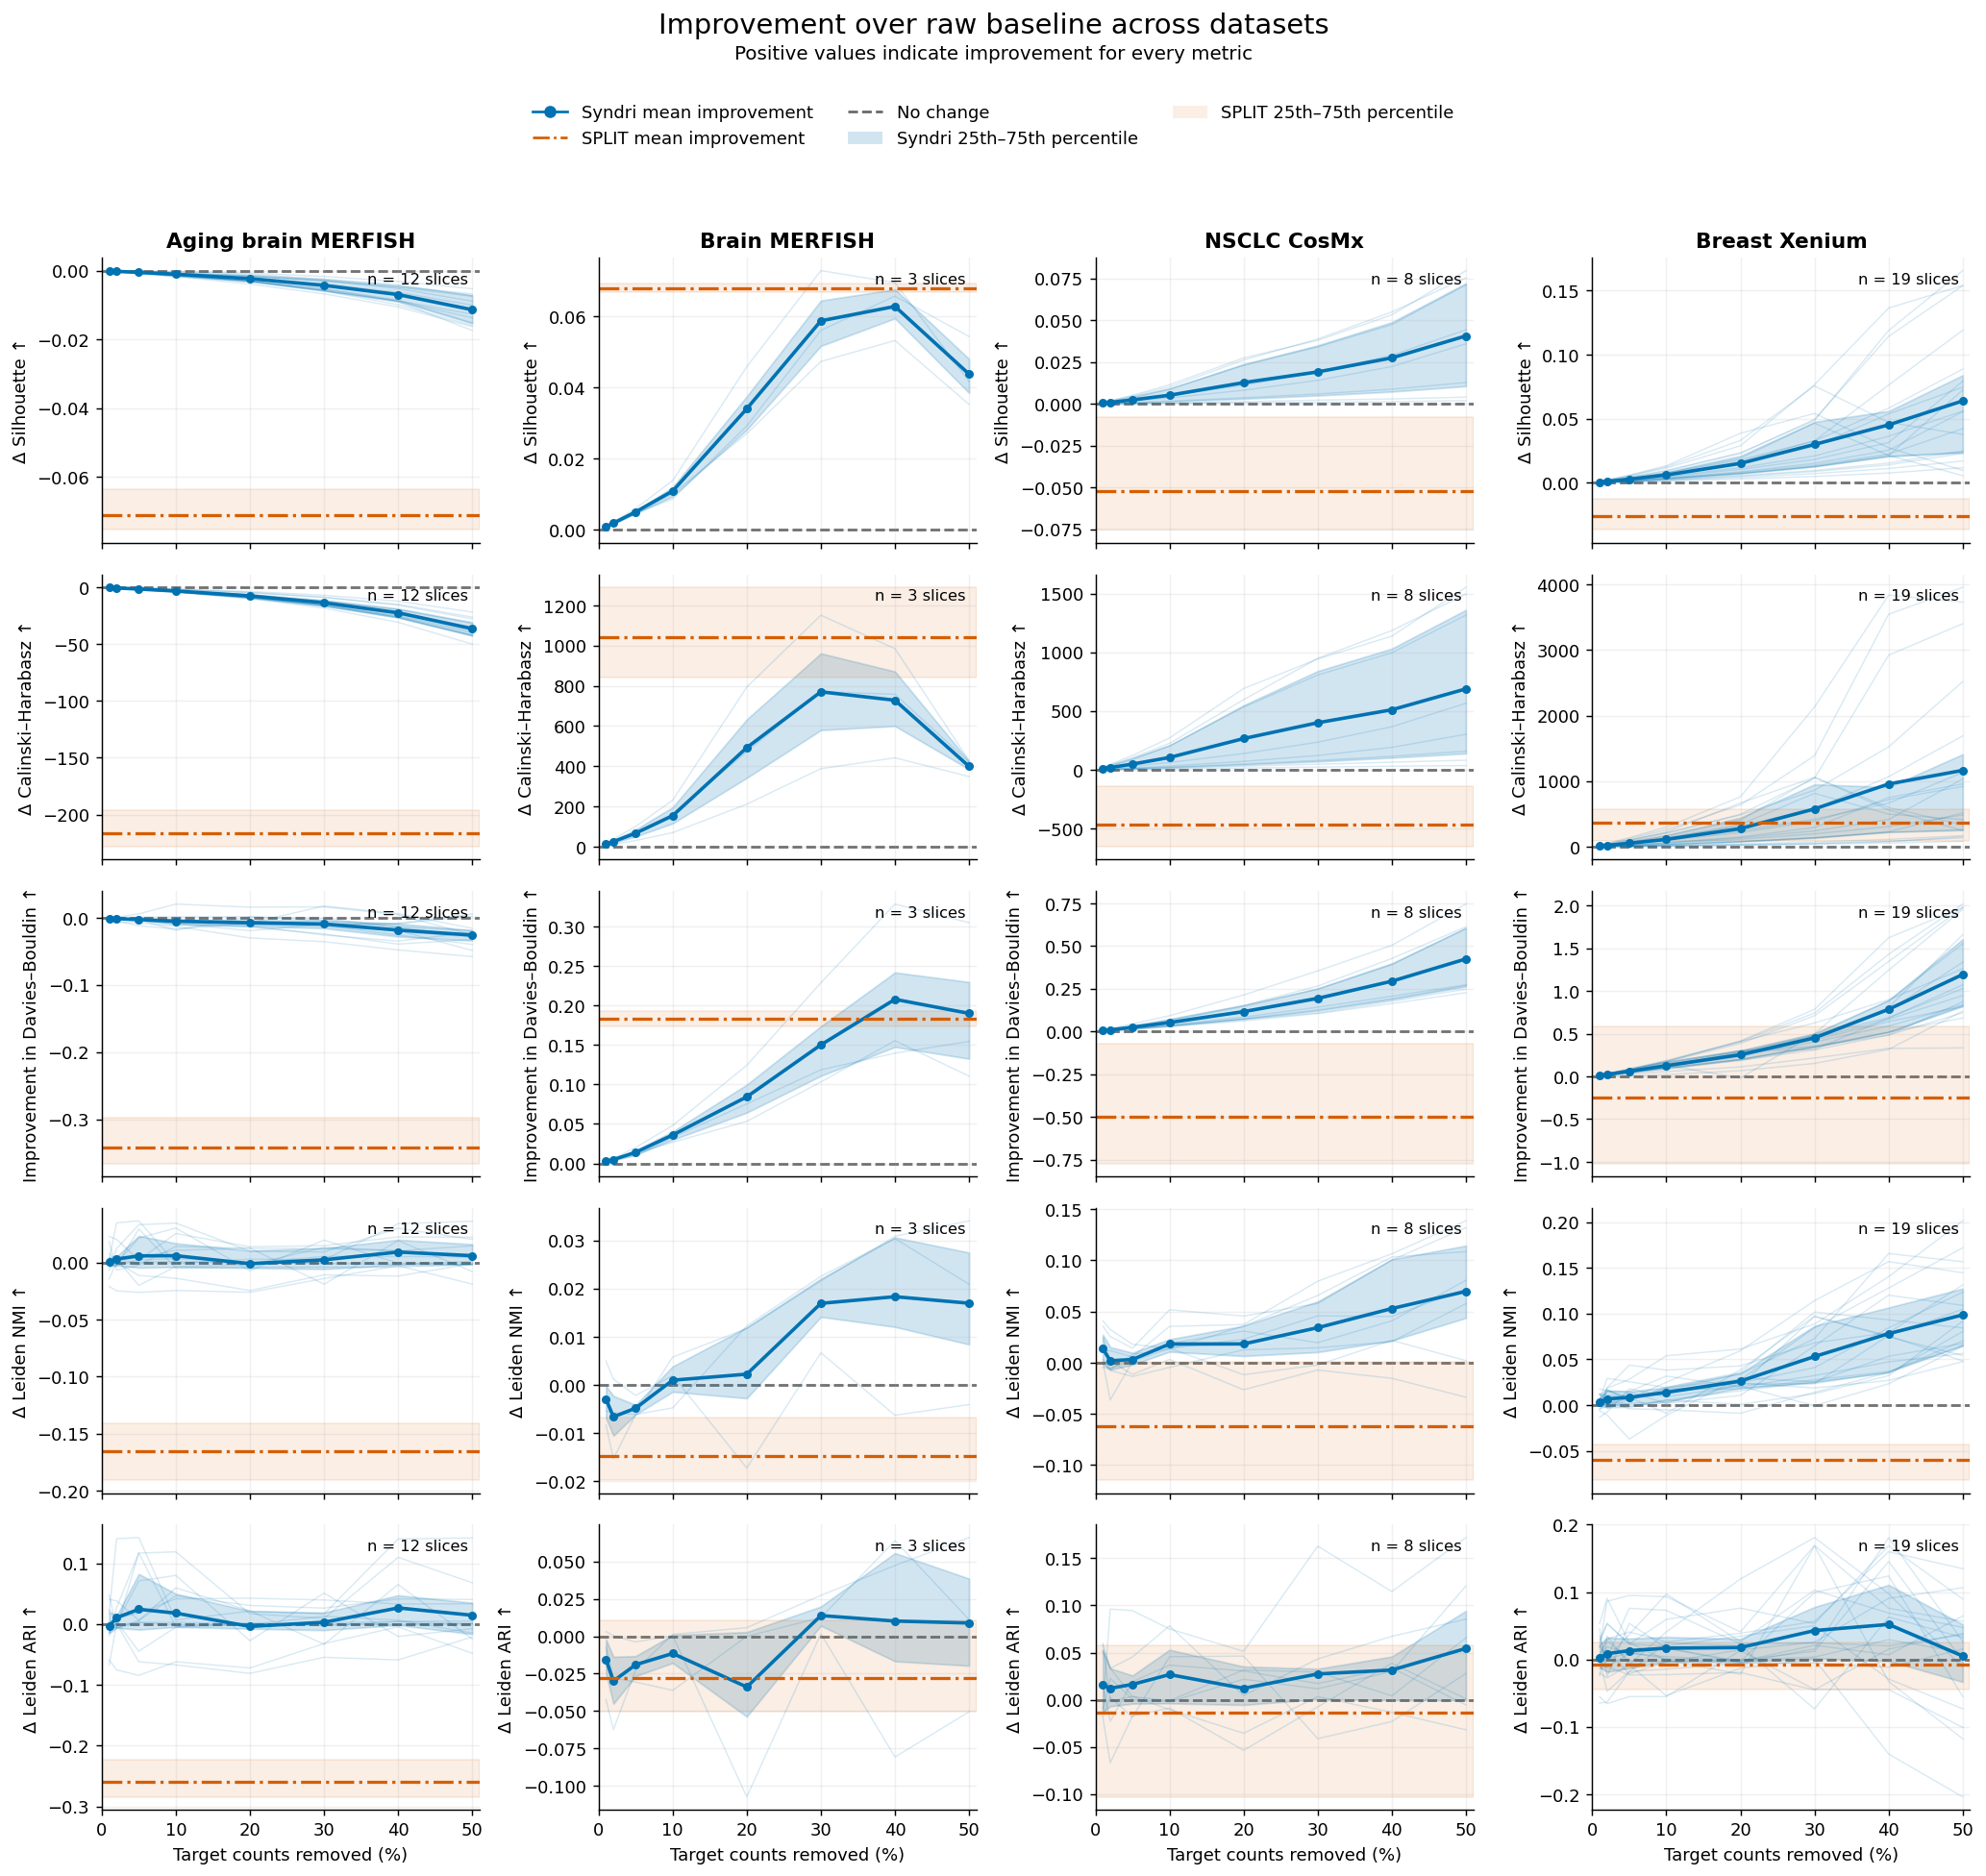

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

df = metrics.loc[metrics["error"].fillna("").eq("")].copy()
df["target_removed_fraction"] = pd.to_numeric(
    df["target_removed_fraction"], errors="coerce"
)

dataset_titles = {
    "agingbrain_merfish": "Aging brain MERFISH",
    "brain_merfish": "Brain MERFISH",
    "nsclc_cosmx": "NSCLC CosMx",
    "breast_xenium": "Breast Xenium",
}

# Direction aligns every metric: positive = improvement over raw.
metric_settings = {
    "silhouette_score": ("Δ Silhouette ↑", 1),
    "calinski_harabasz": ("Δ Calinski–Harabasz ↑", 1),
    "davies_bouldin": ("Improvement in Davies–Bouldin ↑", -1),
    "leiden_nmi_vs_label": ("Δ Leiden NMI ↑", 1),
    "leiden_adjusted_rand_vs_label": ("Δ Leiden ARI ↑", 1),
}

datasets = [d for d in dataset_titles if d in df["dataset"].unique()]
if not datasets:
    raise ValueError("No recognized datasets found.")

syndri_color = "#0072B2"
split_color = "#D55E00"
raw_color = "#666666"

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        len(metric_settings), len(datasets),
        figsize=(4 * len(datasets), 3 * len(metric_settings)),
        sharex=True,
        squeeze=False,
    )

    for col, dataset in enumerate(datasets):
        subset = df.loc[df["dataset"].eq(dataset)]

        for row, (metric, (title, direction)) in enumerate(
            metric_settings.items()
        ):
            ax = axes[row, col]
            data = subset.copy()
            data[metric] = pd.to_numeric(data[metric], errors="coerce")
            data = data.loc[np.isfinite(data[metric])]

            values = data.pivot_table(
                index="slice",
                columns="case",
                values=metric,
                aggfunc="mean",
            )

            sweep = (
                data.loc[
                    data["case"].str.startswith(
                        "cleaned_admixed_removed_frac_", na=False
                    ),
                    ["case", "target_removed_fraction"],
                ]
                .dropna()
                .drop_duplicates()
                .sort_values("target_removed_fraction")
                .drop_duplicates("target_removed_fraction")
            )

            sweep_cases = sweep["case"].tolist()
            required_cases = ["admixed", "SPLIT", *sweep_cases]

            paired = (
                values[required_cases].dropna()
                if sweep_cases and all(c in values for c in required_cases)
                else pd.DataFrame()
            )

            ax.axhline(
                0, color=raw_color, linestyle="--",
                linewidth=1.5, zorder=1,
            )

            if paired.empty:
                ax.text(
                    0.5, 0.5, "Waiting for complete comparisons",
                    ha="center", va="center", transform=ax.transAxes,
                )
            else:
                # Subtract within each slice before calculating summaries.
                # Davies–Bouldin uses raw − method; others use method − raw.
                improvement = (
                    paired.subtract(paired["admixed"], axis=0) * direction
                )

                x = sweep["target_removed_fraction"].to_numpy() * 100
                y = improvement[sweep_cases].to_numpy()
                split_delta = improvement["SPLIT"].to_numpy()

                for slice_delta in y:
                    ax.plot(
                        x, slice_delta, color=syndri_color,
                        alpha=0.15, linewidth=0.8,
                    )

                ax.fill_between(
                    x,
                    np.quantile(y, 0.25, axis=0),
                    np.quantile(y, 0.75, axis=0),
                    color=syndri_color, alpha=0.18,
                )
                ax.plot(
                    x, y.mean(axis=0), "o-",
                    color=syndri_color, linewidth=2, markersize=4,
                )

                ax.axhspan(
                    np.quantile(split_delta, 0.25),
                    np.quantile(split_delta, 0.75),
                    color=split_color, alpha=0.10,
                )
                ax.axhline(
                    split_delta.mean(),
                    color=split_color, linestyle="-.", linewidth=1.8,
                )

                ax.text(
                    0.97, 0.95, f"n = {len(paired)} slices",
                    ha="right", va="top", transform=ax.transAxes,
                    fontsize=9,
                )

            ax.grid(alpha=0.18)
            ax.set_xlim(0, 51)
            ax.set_xticks([0, 10, 20, 30, 40, 50])
            ax.set_ylabel(title)

            if row == 0:
                ax.set_title(dataset_titles[dataset])
            if row == len(metric_settings) - 1:
                ax.set_xlabel("Target counts removed (%)")

    handles = [
        Line2D(
            [0], [0], color=syndri_color, marker="o",
            label="Syndri mean improvement",
        ),
        Line2D(
            [0], [0], color=split_color, linestyle="-.",
            label="SPLIT mean improvement",
        ),
        Line2D(
            [0], [0], color=raw_color, linestyle="--",
            label="No change",
        ),
        Patch(
            facecolor=syndri_color, alpha=0.18,
            label="Syndri 25th–75th percentile",
        ),
        Patch(
            facecolor=split_color, alpha=0.10,
            label="SPLIT 25th–75th percentile",
        ),
    ]

    fig.suptitle(
        "Improvement over raw baseline across datasets",
        y=0.998, fontsize=16,
    )
    fig.text(
        0.5, 0.973,
        "Positive values indicate improvement for every metric",
        ha="center", fontsize=11,
    )
    fig.legend(
        handles=handles, loc="upper center",
        bbox_to_anchor=(0.5, 0.957), ncol=3, frameon=False,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.915])

    # fig.savefig(
    #     "metrics_improvement_from_raw.png",
    #     dpi=300, bbox_inches="tight",
    # )
    # fig.savefig(
    #     "metrics_improvement_from_raw.pdf",
    #     bbox_inches="tight",
    # )
    plt.show()

In [113]:
# Compare each slice's best Syndri result against SPLIT.
# "Best" is selected independently for every slice and metric.

best_rows = []

for dataset in datasets:
    subset = df.loc[df["dataset"].eq(dataset)]

    for metric, (metric_title, direction) in metric_settings.items():
        data = subset.copy()
        data[metric] = pd.to_numeric(data[metric], errors="coerce")
        data = data.loc[np.isfinite(data[metric])]

        values = data.pivot_table(
            index="slice",
            columns="case",
            values=metric,
            aggfunc="mean",
        )

        sweep = (
            data.loc[
                data["case"].str.startswith(
                    "cleaned_admixed_removed_frac_", na=False
                ),
                ["case", "target_removed_fraction"],
            ]
            .dropna()
            .drop_duplicates()
            .sort_values("target_removed_fraction")
            .drop_duplicates("target_removed_fraction")
        )

        sweep_cases = sweep["case"].tolist()
        fraction_by_case = dict(
            zip(sweep["case"], sweep["target_removed_fraction"])
        )
        required_cases = ["admixed", "SPLIT", *sweep_cases]

        if not sweep_cases or any(case not in values for case in required_cases):
            continue

        paired = values[required_cases].dropna()
        if paired.empty:
            continue

        # Positive means better than raw for every metric.
        improvement = (
            paired.subtract(paired["admixed"], axis=0) * direction
        )

        for slice_name, row_values in improvement.iterrows():
            best_case = row_values[sweep_cases].idxmax()

            best_syndri = row_values[best_case]
            split = row_values["SPLIT"]

            best_rows.append({
                "dataset": dataset,
                "slice": slice_name,
                "metric": metric,
                "metric_title": metric_title.replace("Δ ", ""),
                "best_syndri_improvement": best_syndri,
                "split_improvement": split,
                "best_syndri_minus_split": best_syndri - split,
                "best_removed_fraction": fraction_by_case[best_case],
                "best_removed_percent": (
                    fraction_by_case[best_case] * 100
                ),
            })

best_comparison = pd.DataFrame(best_rows)

display(
    best_comparison.sort_values(
        ["dataset", "metric", "slice"]
    ).head()
)

,dataset,slice,metric,metric_title,best_syndri_improvement,split_improvement,best_syndri_minus_split,best_removed_fraction,best_removed_percent
12,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,calinski_harabasz,Calinski–Harabasz ↑,-0.335546,-223.402849,223.067303,0.01,1.0
13,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_1,calinski_harabasz,Calinski–Harabasz ↑,-0.350275,-176.413527,176.063252,0.01,1.0
14,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_2,calinski_harabasz,Calinski–Harabasz ↑,-0.250578,-154.054390,153.803812,0.01,1.0
15,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_0,calinski_harabasz,Calinski–Harabasz ↑,-0.337954,-204.821846,204.483891,0.01,1.0
16,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_1,calinski_harabasz,Calinski–Harabasz ↑,-0.368508,-218.691666,218.323158,0.01,1.0


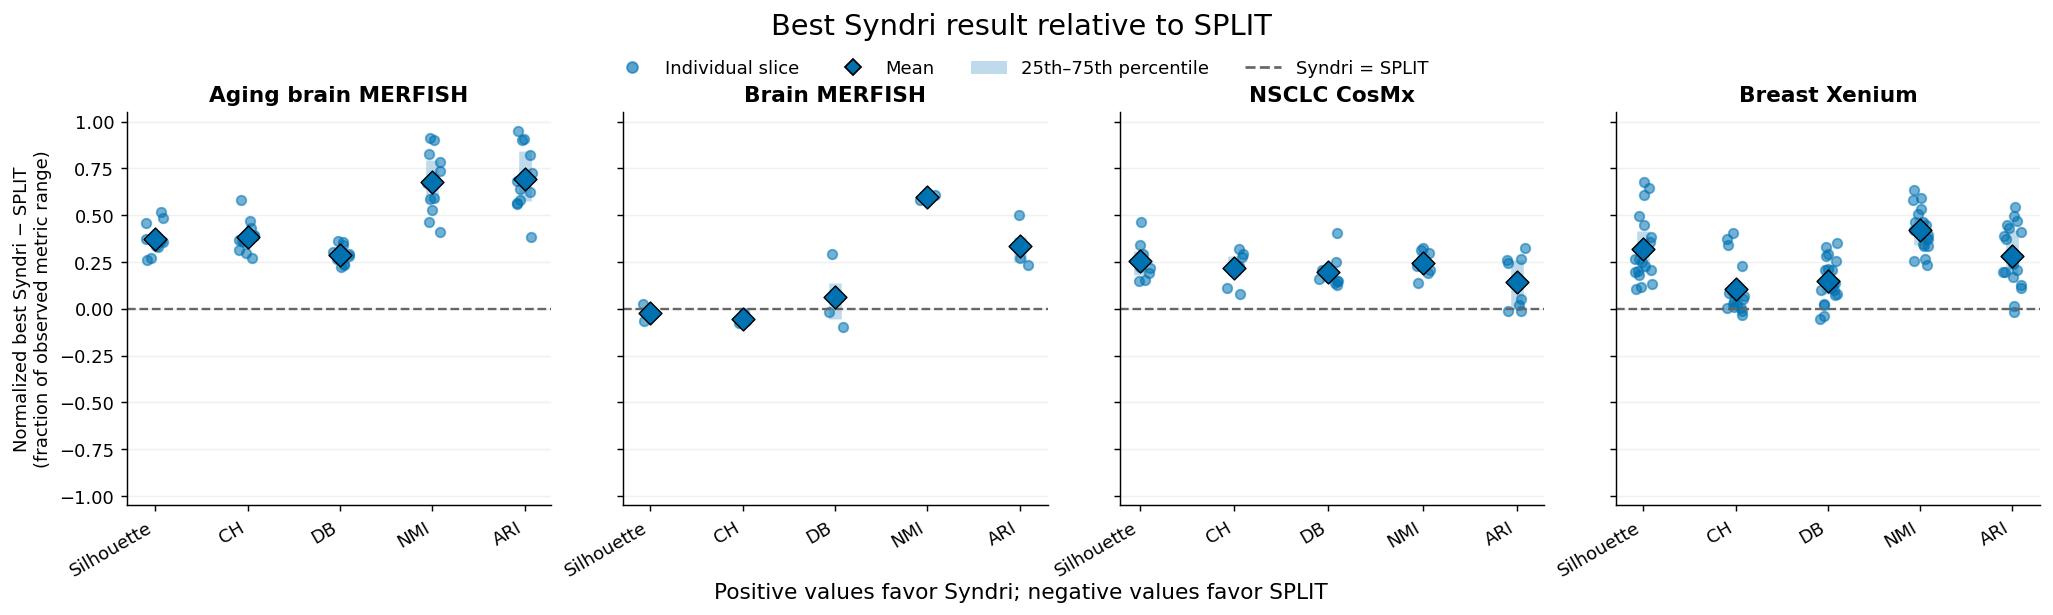

In [124]:
dataset_order = datasets
metric_order = list(metric_settings)

metric_labels = {
    "silhouette_score": "Silhouette",
    "calinski_harabasz": "CH",
    "davies_bouldin": "DB",
    "leiden_nmi_vs_label": "NMI",
    "leiden_adjusted_rand_vs_label": "ARI",
}

best_color = "#0072B2"
zero_color = "#666666"
rng = np.random.default_rng(0)

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        1,
        len(dataset_order),
        figsize=(4 * len(dataset_order), 4.8),
        sharey=True,
        squeeze=False,
        # constrained_layout=True,
    )

    for col, dataset in enumerate(dataset_order):
        ax = axes[0, col]

        plot_data = best_comparison_normalized.loc[
            best_comparison_normalized["dataset"].eq(dataset)
        ].copy()

        positions = np.arange(len(metric_order))

        for position, metric in zip(positions, metric_order):
            values = plot_data.loc[
                plot_data["metric"].eq(metric),
                "normalized_syndri_minus_split",
            ].dropna()

            if values.empty:
                continue

            jitter = rng.uniform(-0.10, 0.10, len(values))

            # Individual slices.
            ax.scatter(
                np.full(len(values), position) + jitter,
                values,
                color=best_color,
                alpha=0.55,
                s=28,
                zorder=2,
            )

            # Interquartile range.
            ax.vlines(
                position,
                values.quantile(0.25),
                values.quantile(0.75),
                color=best_color,
                linewidth=7,
                alpha=0.25,
                zorder=1,
            )

            # Mean.
            ax.scatter(
                position,
                values.mean(),
                color=best_color,
                edgecolor="black",
                marker="D",
                s=80,
                linewidth=0.8,
                zorder=3,
            )

        ax.axhline(
            0,
            color=zero_color,
            linestyle="--",
            linewidth=1.3,
        )

        ax.set_xticks(positions)
        ax.set_xticklabels(
            [metric_labels[m] for m in metric_order],
            rotation=30,
            ha="right",
        )
        ax.set_title(dataset_titles[dataset])
        ax.set_ylim(-1.05, 1.05)
        ax.set_yticks(np.arange(-1, 1.01, 0.25))
        ax.grid(axis="y", alpha=0.18)

        if col == 0:
            ax.set_ylabel(
                "Normalized best Syndri − SPLIT\n"
                "(fraction of observed metric range)"
            )

    handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=best_color,
            alpha=0.65,
            label="Individual slice",
        ),
        Line2D(
            [0], [0],
            marker="D",
            markeredgecolor="black",
            linestyle="",
            color=best_color,
            label="Mean",
        ),
        Patch(
            facecolor=best_color,
            alpha=0.25,
            label="25th–75th percentile",
        ),
        Line2D(
            [0], [0],
            color=zero_color,
            linestyle="--",
            label="Syndri = SPLIT",
        ),
    ]

    fig.suptitle(
    "Best Syndri result relative to SPLIT",
    fontsize=16,
    y=0.98,
)

fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=4,
    frameon=False,
)

fig.supxlabel(
    "Positive values favor Syndri; negative values favor SPLIT",
    y=0.035,
)

# Reserve explicit space for the title, legend, and bottom caption.
fig.subplots_adjust(
    top=0.82,
    bottom=0.19,
    left=0.07,
    right=0.99,
    wspace=0.17,
)

# fig.savefig(
#     "best_syndri_vs_split_normalized.png",
#     dpi=300,
#     bbox_inches="tight",
# )
# fig.savefig(
#     "best_syndri_vs_split_normalized.pdf",
#     bbox_inches="tight",
# )
plt.show()


In [98]:
datasets

['agingbrain_merfish', 'brain_merfish', 'nsclc_cosmx', 'breast_xenium']

In [127]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

root = Path("/work/magroup/skrieger/Syndri/data/datasets")

dataset_titles = {
    "breast_xenium": "Breast Xenium",
    "nsclc_cosmx": "NSCLC CosMx",
}

result_types = {
    "contamination": "tcell_contamination_metrics.csv",
    "effects": "tcell_contamination_effects.csv",
    "cosine": "tcell_cosine_similarity.csv",
    "genes": "tcell_lr_top_genes.csv",
    "profiles": "tissue_cell_type_profiles.csv",
}


def load_tcell_results(result_type):
    filename = result_types[result_type]
    frames = []

    for dataset in dataset_titles:
        search_root = root / dataset / "results/metrics/tcell"

        for path in sorted(search_root.glob(f"*/{filename}")):
            if path.stat().st_size == 0:
                continue

            try:
                frame = pd.read_csv(path)
            except pd.errors.EmptyDataError:
                continue

            frame["dataset"] = dataset
            frame["slice"] = path.parent.name
            frame["result_path"] = str(path)
            frames.append(frame)

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)


tcell_contamination = load_tcell_results("contamination")
tcell_effects = load_tcell_results("effects")
tcell_cosine = load_tcell_results("cosine")
tcell_genes = load_tcell_results("genes")
tcell_profiles = load_tcell_results("profiles")

print("Loaded rows:")
print("  contamination:", len(tcell_contamination))
print("  effects:", len(tcell_effects))
print("  cosine:", len(tcell_cosine))
print("  genes:", len(tcell_genes))
print("  profiles:", len(tcell_profiles))

print("\nCompleted slices:")
for dataset in dataset_titles:
    n = tcell_contamination.loc[
        tcell_contamination["dataset"].eq(dataset), "slice"
    ].nunique()
    print(f"  {dataset}: {n}")

def valid_rows(frame):
    if frame.empty:
        return frame.copy()

    result = frame.copy()

    if "error" in result:
        result = result.loc[result["error"].fillna("").eq("")]

    result["target_removed_fraction"] = pd.to_numeric(
        result.get("target_removed_fraction"),
        errors="coerce",
    )
    return result


def paired_improvement(
    frame,
    value_col,
    pair_cols,
    direction=1,
    raw_case="raw_X",
):
    """
    direction=1:  larger values are better
    direction=-1: smaller values are better

    Returned improvement is oriented so positive always means better than raw.
    """
    data = valid_rows(frame)
    data[value_col] = pd.to_numeric(data[value_col], errors="coerce")
    data = data.loc[np.isfinite(data[value_col])].copy()

    raw = (
        data.loc[data["condition"].eq(raw_case), pair_cols + [value_col]]
        .groupby(pair_cols, observed=True)[value_col]
        .mean()
        .rename("raw_value")
        .reset_index()
    )

    paired = data.merge(
        raw,
        on=pair_cols,
        how="inner",
        validate="many_to_one",
    )

    paired["improvement_from_raw"] = (
        paired[value_col] - paired["raw_value"]
    ) * direction

    return paired

contamination_delta = paired_improvement(
    tcell_contamination,
    value_col="marker_overlap_frac",
    pair_cols=[
        "dataset",
        "slice",
        "target_cell_type_i",
        "contaminating_cell_type_j",
    ],
    direction=-1,  # Less contaminating-marker overlap is better.
)

cosine_delta = paired_improvement(
    tcell_cosine,
    value_col="cosine_similarity",
    pair_cols=[
        "dataset",
        "slice",
        "spatial_cell_type",
        "reference_cell_type",
    ],
    direction=1,  # Greater reference similarity is better.
)

/tmp/ipykernel_708438/2639787932.py:37: DtypeWarning: Columns (18,19,20) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_708438/2639787932.py:37: DtypeWarning: Columns (18,19,20) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_708438/2639787932.py:37: DtypeWarning: Columns (18,19,20) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)
/tmp/ipykernel_708438/2639787932.py:37: DtypeWarning: Columns (18,19,20) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(path)


Loaded rows:
  contamination: 37160
  effects: 3716
  cosine: 810
  genes: 743200
  profiles: 1658550

Completed slices:
  breast_xenium: 19
  nsclc_cosmx: 8


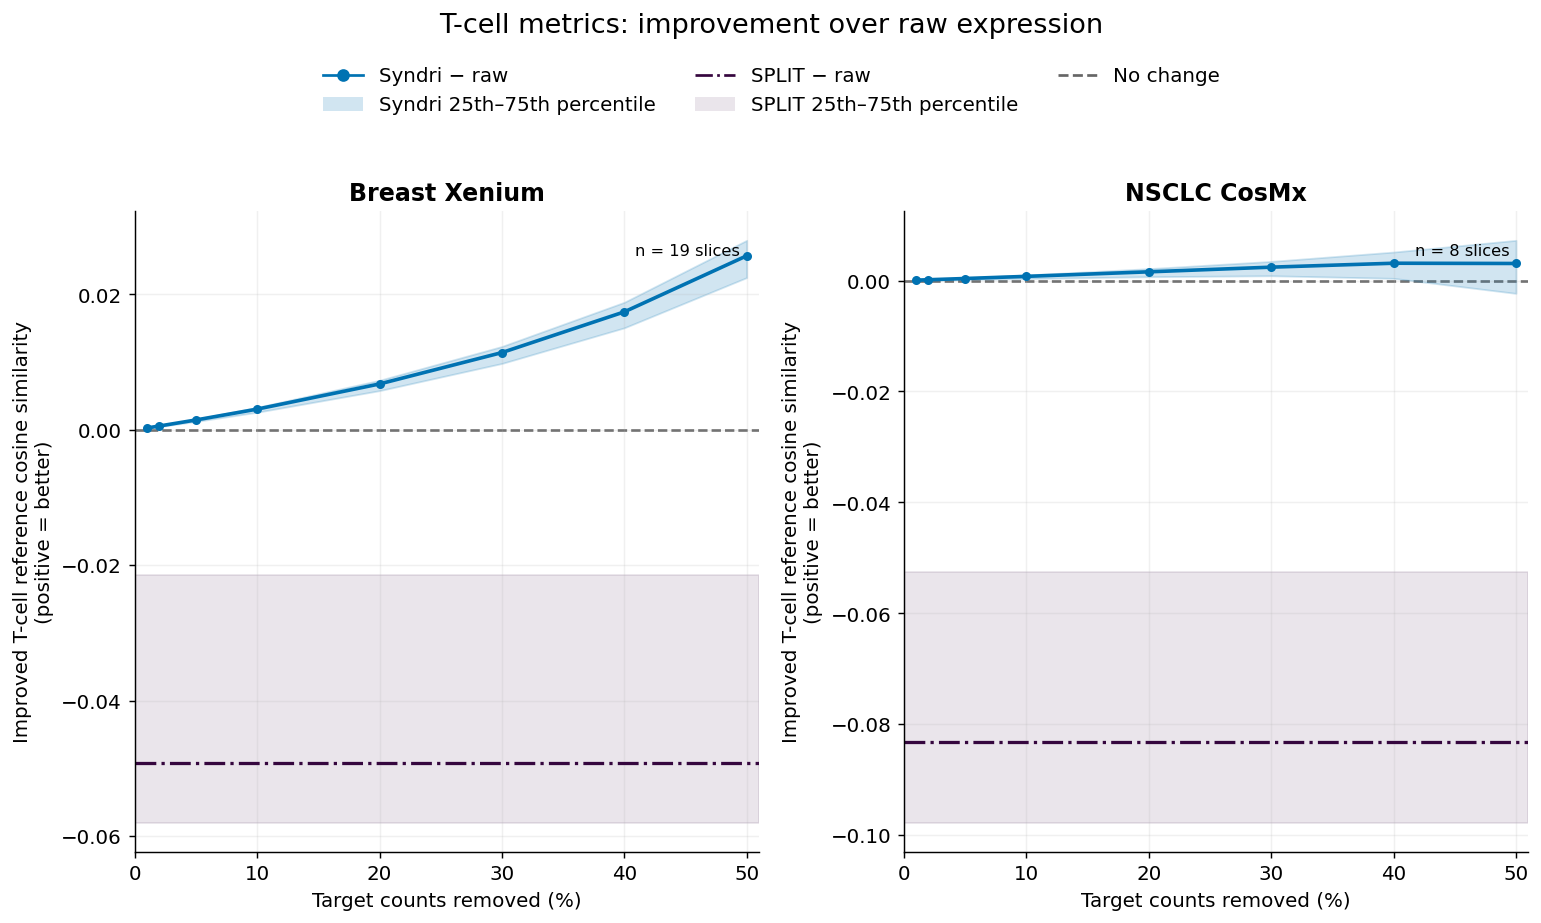

In [128]:
syndri_color = "#0072B2"
split_color = "#35063E"
zero_color = "#666666"

metric_specs = [
    # (
    #     contamination_delta,
    #     "Reduced contaminating-marker overlap",
    # ),
    (
        cosine_delta,
        "Improved T-cell reference cosine similarity",
    ),
]

with plt.rc_context({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "figure.dpi": 130,
}):
    fig, axes = plt.subplots(
        nrows=len(metric_specs),
        ncols=len(dataset_titles),
        figsize=(12, 7),
        sharex=True,
        squeeze=False,
    )

    for col, (dataset, dataset_title) in enumerate(dataset_titles.items()):
        for row, (table, ylabel) in enumerate(metric_specs):
            ax = axes[row, col]
            subset = table.loc[table["dataset"].eq(dataset)].copy()

            ax.axhline(
                0,
                color=zero_color,
                linestyle="--",
                linewidth=1.4,
                zorder=1,
            )

            # Syndri removal-fraction cases.
            syndri = subset.loc[
                subset["condition"].str.startswith(
                    "cleaned_admixed_removed_frac_", na=False
                )
                & subset["target_removed_fraction"].notna()
            ].copy()

            summary = (
                syndri.groupby("target_removed_fraction", observed=True)
                ["improvement_from_raw"]
                .agg(
                    mean="mean",
                    q25=lambda x: x.quantile(0.25),
                    q75=lambda x: x.quantile(0.75),
                    n="size",
                )
                .reset_index()
                .sort_values("target_removed_fraction")
            )

            if not summary.empty:
                x = summary["target_removed_fraction"].to_numpy() * 100

                ax.fill_between(
                    x,
                    summary["q25"].to_numpy(),
                    summary["q75"].to_numpy(),
                    color=syndri_color,
                    alpha=0.18,
                )
                ax.plot(
                    x,
                    summary["mean"].to_numpy(),
                    "o-",
                    color=syndri_color,
                    linewidth=2,
                    markersize=4,
                )

            # SPLIT is independent of the Syndri removal fraction.
            split = subset.loc[
                subset["condition"].eq("SPLIT"),
                "improvement_from_raw",
            ].dropna()

            if not split.empty:
                ax.axhspan(
                    split.quantile(0.25),
                    split.quantile(0.75),
                    color=split_color,
                    alpha=0.10,
                )
                ax.axhline(
                    split.mean(),
                    color=split_color,
                    linestyle="-.",
                    linewidth=1.8,
                )

            n_slices = subset["slice"].nunique()
            ax.text(
                0.97,
                0.95,
                f"n = {n_slices} slices",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=9,
            )

            if row == 0:
                ax.set_title(dataset_title)

            ax.set_ylabel(ylabel + "\n(positive = better)")
            ax.set_xlim(0, 51)
            ax.set_xticks([0, 10, 20, 30, 40, 50])
            ax.grid(alpha=0.18)

            if row == len(metric_specs) - 1:
                ax.set_xlabel("Target counts removed (%)")

    legend = [
        Line2D(
            [0], [0],
            color=syndri_color,
            marker="o",
            label="Syndri − raw",
        ),
        Patch(
            facecolor=syndri_color,
            alpha=0.18,
            label="Syndri 25th–75th percentile",
        ),
        Line2D(
            [0], [0],
            color=split_color,
            linestyle="-.",
            label="SPLIT − raw",
        ),
        Patch(
            facecolor=split_color,
            alpha=0.10,
            label="SPLIT 25th–75th percentile",
        ),
        Line2D(
            [0], [0],
            color=zero_color,
            linestyle="--",
            label="No change",
        ),
    ]

    fig.legend(
        handles=legend,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=3,
        frameon=False,
    )
    fig.suptitle(
        "T-cell metrics: improvement over raw expression",
        y=1.01,
        fontsize=15,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.90])

    fig.savefig(
        "tcell_metrics_improvement.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        "tcell_metrics_improvement.pdf",
        bbox_inches="tight",
    )
    plt.show()